![Logo SENATI](../static/logo_senati.png)

**SENATI | Escuela de Tecnologías de la Información**  
**Taller: Machine Learning y Deep Learning**  
*Instructor: Ing. Gunar Castro Iñigo*

---

# Estimación de pedidos de kits de robótica — caso práctico intermedio 01

**Contexto:** Una tienda educativa quiere anticipar sus pedidos semanales. Más consultas web y más inversión en publicidad pueden asociarse con más ventas; la campaña escolar se marca con 1 (hay campaña) o 0 (no hay).

**Objetivo:** aplicar regresión múltiple desde la lectura de datos hasta una web pequeña con Flask.

## Paso 1. Explorar el CSV
Entradas `X`: `consultas_web`, `inversion_publicidad_soles`, `campana_escolar`. Respuesta `y`: `pedidos_kits`.

**Los datos son simulados**, no registros reales.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

datos = pd.read_csv('../caso_01_pedidos_kits/datos.csv', encoding='utf-8-sig')
print(datos.head())
print()
print('Filas y columnas:', datos.shape)
print('Ausentes por columna:')
print(datos.isna().sum())
print('Filas duplicadas:', datos.duplicated().sum())
datos.describe().round(2)

  semana  consultas_web  inversion_publicidad_soles  campana_escolar  \
0   S001             31                         600                1   
1   S002             51                          75                0   
2   S003             27                         900                0   
3   S004             45                         125                0   
4   S005             40                         225                1   

   pedidos_kits  
0            22  
1            20  
2            17  
3            21  
4            16  

Filas y columnas: (110, 5)
Ausentes por columna:
semana                        0
consultas_web                 0
inversion_publicidad_soles    0
campana_escolar               0
pedidos_kits                  0
dtype: int64
Filas duplicadas: 0


,consultas_web,inversion_publicidad_soles,campana_escolar,pedidos_kits
count,110.00,110.00,110.00,110.00
mean,32.22,577.73,0.51,19.36
std,18.69,323.26,0.50,7.73
min,5.00,0.00,0.00,3.00
25%,14.25,300.00,0.00,14.25
50%,30.50,600.00,1.00,20.00
75%,48.50,850.00,1.00,25.00
max,69.00,1100.00,1.00,41.00


consultas_web                 0.806
inversion_publicidad_soles    0.260
campana_escolar               0.176
pedidos_kits                  1.000
Name: pedidos_kits, dtype: float64


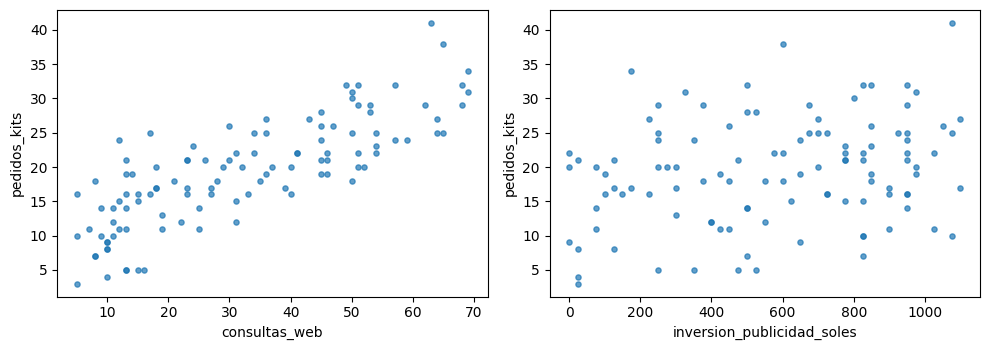

In [2]:
# Relación de cada variable de entrada con la respuesta
columnas = ['consultas_web', 'inversion_publicidad_soles', 'campana_escolar']
objetivo = 'pedidos_kits'
print(datos[columnas + [objetivo]].corr()[objetivo].round(3))

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.6))
for eje, col in zip(ejes, columnas[:2]):
    eje.scatter(datos[col], datos[objetivo], s=14, alpha=.7)
    eje.set_xlabel(col); eje.set_ylabel(objetivo)
plt.tight_layout(); plt.show()

**Lectura del gráfico:** las dos variables numéricas muestran una relación creciente con la respuesta, por eso tiene sentido probar una regresión lineal. Las variables 0/1 funcionan como un interruptor que suma o resta un monto fijo.

## Paso 2. Separar y entrenar
Se reserva 20 % de las filas para **probar**; el modelo solo aprende del 80 % restante.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

X = datos[columnas]
y = datos[objetivo]

X_ent, X_prueba, y_ent, y_prueba = train_test_split(X, y, test_size=0.2, random_state=42)
print('Entrenamiento:', len(X_ent), 'filas | Prueba:', len(X_prueba), 'filas')

modelo = LinearRegression()
modelo.fit(X_ent, y_ent)

print('Intercepto:', round(modelo.intercept_, 4))
for nombre, coef in zip(columnas, modelo.coef_):
    print(f'  {nombre}: {coef:.4f}')

Entrenamiento: 88 filas | Prueba: 22 filas
Intercepto: 1.5385
  consultas_web: 0.3463
  inversion_publicidad_soles: 0.0067
  campana_escolar: 5.0182


**Interpretación de los coeficientes:** cada consulta web adicional suma ≈ 0.35 pedidos; cada S/ 100 de publicidad suma ≈ 0.67 pedidos (efecto pequeño); si hay campaña escolar se esperan ≈ 5 pedidos más. El intercepto (≈ 1.5) es el punto de partida del cálculo.

## Paso 3. Evaluar con los datos de prueba

MAE = 2.954
R²  = 0.791
Error promedio relativo ≈ 15.3 % del valor promedio (19.4)


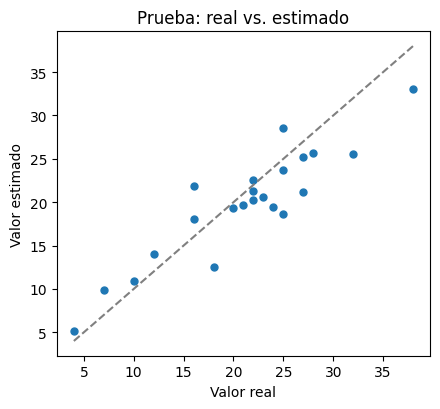

In [4]:
pred = modelo.predict(X_prueba)
mae = mean_absolute_error(y_prueba, pred)
r2 = r2_score(y_prueba, pred)
print(f'MAE = {mae:.3f}')
print(f'R²  = {r2:.3f}')
print(f'Error promedio relativo ≈ {mae / y.mean() * 100:.1f} % del valor promedio ({y.mean():.1f})')

plt.figure(figsize=(4.5, 4.2))
plt.scatter(y_prueba, pred, s=25)
lim = [min(y_prueba.min(), pred.min()), max(y_prueba.max(), pred.max())]
plt.plot(lim, lim, color='gray', linestyle='--')
plt.xlabel('Valor real'); plt.ylabel('Valor estimado'); plt.title('Prueba: real vs. estimado')
plt.tight_layout(); plt.show()

**MAE:** en promedio la estimación se equivoca por unos 3 pedidos por semana (≈ 15 % del promedio de 19 pedidos).  
**R²:** el modelo explica ≈ 79 % de la variación de los pedidos; el resto depende de factores que no están en el CSV.

## Paso 4. Guardar `modelo.json`
La web leerá estos números; no necesita Scikit-learn en el hosting.

In [5]:
resumen = {
    'caso': 'caso-01',
    'columnas': columnas,
    'objetivo': objetivo,
    'intercepto': float(modelo.intercept_),
    'coeficientes': {c: float(k) for c, k in zip(columnas, modelo.coef_)},
    'mae': float(mae),
    'r2': float(r2),
}
print(json.dumps(resumen, indent=2, ensure_ascii=False))
# Nota: el archivo final modelo.json lo genera entrenar.py (con los mismos números y más datos para la web).

{
  "caso": "caso-01",
  "columnas": [
    "consultas_web",
    "inversion_publicidad_soles",
    "campana_escolar"
  ],
  "objetivo": "pedidos_kits",
  "intercepto": 1.5384729585592574,
  "coeficientes": {
    "consultas_web": 0.3463033562740661,
    "inversion_publicidad_soles": 0.006699109182241925,
    "campana_escolar": 5.018213367145449
  },
  "mae": 2.954102420565232,
  "r2": 0.7910735136647091
}


## Paso 5. Pruebas obligatorias

In [6]:
pruebas = [
    ('Semana con 20 consultas, S/ 200 y sin campaña', {'consultas_web': 20, 'inversion_publicidad_soles': 200, 'campana_escolar': 0}),
    ('Semana con 55 consultas, S/ 800 y con campaña', {'consultas_web': 55, 'inversion_publicidad_soles': 800, 'campana_escolar': 1}),
]
for nombre, valores in pruebas:
    fila = pd.DataFrame([valores])[columnas]
    estimado = max(modelo.predict(fila)[0], 0)
    print(f'{nombre}: {estimado:.2f} pedidos')

Semana con 20 consultas, S/ 200 y sin campaña: 9.80 pedidos
Semana con 55 consultas, S/ 800 y con campaña: 30.96 pedidos


**¿Tienen sentido?** Sí: 20 consultas, S/ 200 y sin campaña da ≈ 10 pedidos (semana floja); 55 consultas, S/ 800 y con campaña da ≈ 31 pedidos (semana fuerte). Ambos valores están dentro del rango de los datos (3 a 41 pedidos).

**¿Cuándo puede fallar?** Con valores fuera de los rangos (5–70 consultas, S/ 0–1100), con feriados o quiebres de stock, y porque los datos son simulados.

## Conclusiones
- La regresión lineal múltiple se ajusta bien a estos datos simulados.
- Las métricas se calcularon solo con datos de prueba, que el modelo no vio al entrenar.
- La estimación es una **referencia**, no una garantía: con pocos datos, otra separación cambiaría un poco el MAE y el R².
- La web en Flask valida rangos y muestra una advertencia de estimación.